In [58]:
import sys
from datasets import load_dataset
import pandas as pd
import numpy as np

from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

In [59]:
loader = HFDatasetLoader(
    dataset_name="electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all",
    split="train",
    filename="datos/africa-synth-climate-deforestation-land-use-change-all.csv",
)

In [60]:
df = loader.load()
df.head(2)

,record_id,country,year,region_type,forest_cover_pct,forest_area_ha,population_density,agricultural_expansion_index,deforestation_rate_ha_year,primary_driver,land_conversion_type,policy_strength_index,protected_area_coverage,biomass_loss_tonnes,carbon_emission_tonnes,biodiversity_impact_score,climate_regulation_loss_usd,recovery_potential_index
0,DEF_000000,Niger,2020,peri-urban,0.94,1161078,77.9,0.747,25725,charcoal_production,mining_area,0.712,6.1,71870,38903,2.99,10510735,0.874
1,DEF_000001,Uganda,2022,frontier,11.42,2277928,34.9,0.432,88741,smallholder_agriculture,secondary_forest,0.612,7.0,2120668,1002209,10.00,68265943,0.575


## Regresion lineal

In [61]:
df["forest_cover_pct"].head()

0     0.94
1    11.42
2    55.68
3    20.44
4    15.65
Name: forest_cover_pct, dtype: float64

In [62]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

# Seleccionar variables del dataset de Hugging Face
X = df[[
    "forest_cover_pct",
    "population_density",
    "agricultural_expansion_index",
    "policy_strength_index",
    "protected_area_coverage",
    "year"
]]

y = df["deforestation_rate_ha_year"]

# Preparar datos: eliminar filas con valores faltantes
datos_modelo = X.join(y).dropna()
X = datos_modelo[X.columns]
y = datos_modelo["deforestation_rate_ha_year"]

# Inicializar modelo
modelo = LinearRegression()

# Dividir datos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Entrenamiento
modelo.fit(X_train, y_train)

# Predicción
predicciones = modelo.predict(X_test)

# Evaluación del modelo
print(f"MAE: {mean_absolute_error(y_test, predicciones):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predicciones)):.2f}")
print(f"R2: {r2_score(y_test, predicciones):.2f}")

# Coeficientes e intercepto
print("\nCoeficientes del modelo:")
for variable, coeficiente in zip(X.columns, modelo.coef_):
    print(f"{variable}: {coeficiente:.4f}")

print(f"\nIntercepto (b): {modelo.intercept_:.2f}")


MAE: 478266.08
RMSE: 802751.63
R2: 0.41

Coeficientes del modelo:
forest_cover_pct: 35822.7030
population_density: -1255.5256
agricultural_expansion_index: 1148737.6256
policy_strength_index: -40157.1508
protected_area_coverage: -2716.0859
year: 14637.2816

Intercepto (b): -30370237.57


In [63]:
%pip install --upgrade matplotlib

Note: you may need to restart the kernel to use updated packages.


In [64]:
%matplotlib inline

In [65]:
import sys
import matplotlib

print(sys.executable)
print(matplotlib.__version__)

/workspaces/MachineLearning/.venv/bin/python
3.11.2


In [66]:
import matplotlib.pyplot as plt
from IPython.display import display

x_test = X_test["protected_area_coverage"].to_numpy()
y_test_array = y_test.to_numpy()
orden = x_test.argsort()

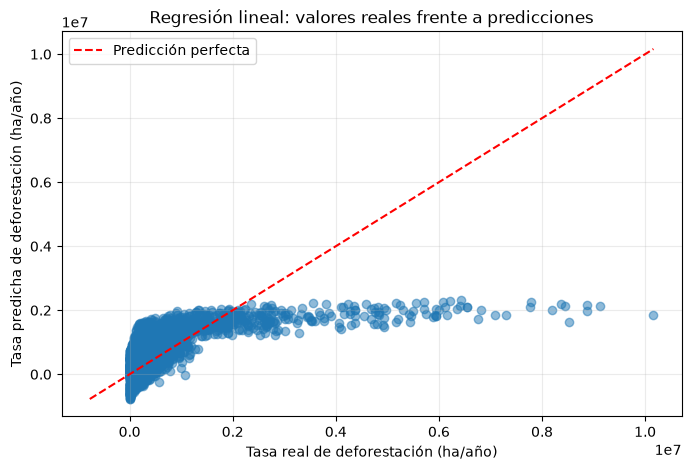

In [67]:

import matplotlib.pyplot as plt
from IPython.display import display

# Preparar los valores reales y las predicciones
y_test_array = y_test.to_numpy()
predicciones_array = np.asarray(predicciones)

# Gráfica: valores reales frente a valores predichos
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    y_test_array,
    predicciones_array,
    alpha=0.5
)

# Línea de referencia: predicción perfecta
limite_min = min(y_test_array.min(), predicciones_array.min())
limite_max = max(y_test_array.max(), predicciones_array.max())

ax.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    color="red",
    linestyle="--",
    label="Predicción perfecta"
)

ax.set_xlabel("Tasa real de deforestación (ha/año)")
ax.set_ylabel("Tasa predicha de deforestación (ha/año)")
ax.set_title("Regresión lineal: valores reales frente a predicciones")
ax.legend()
ax.grid(alpha=0.25)

display(fig)
plt.close(fig)

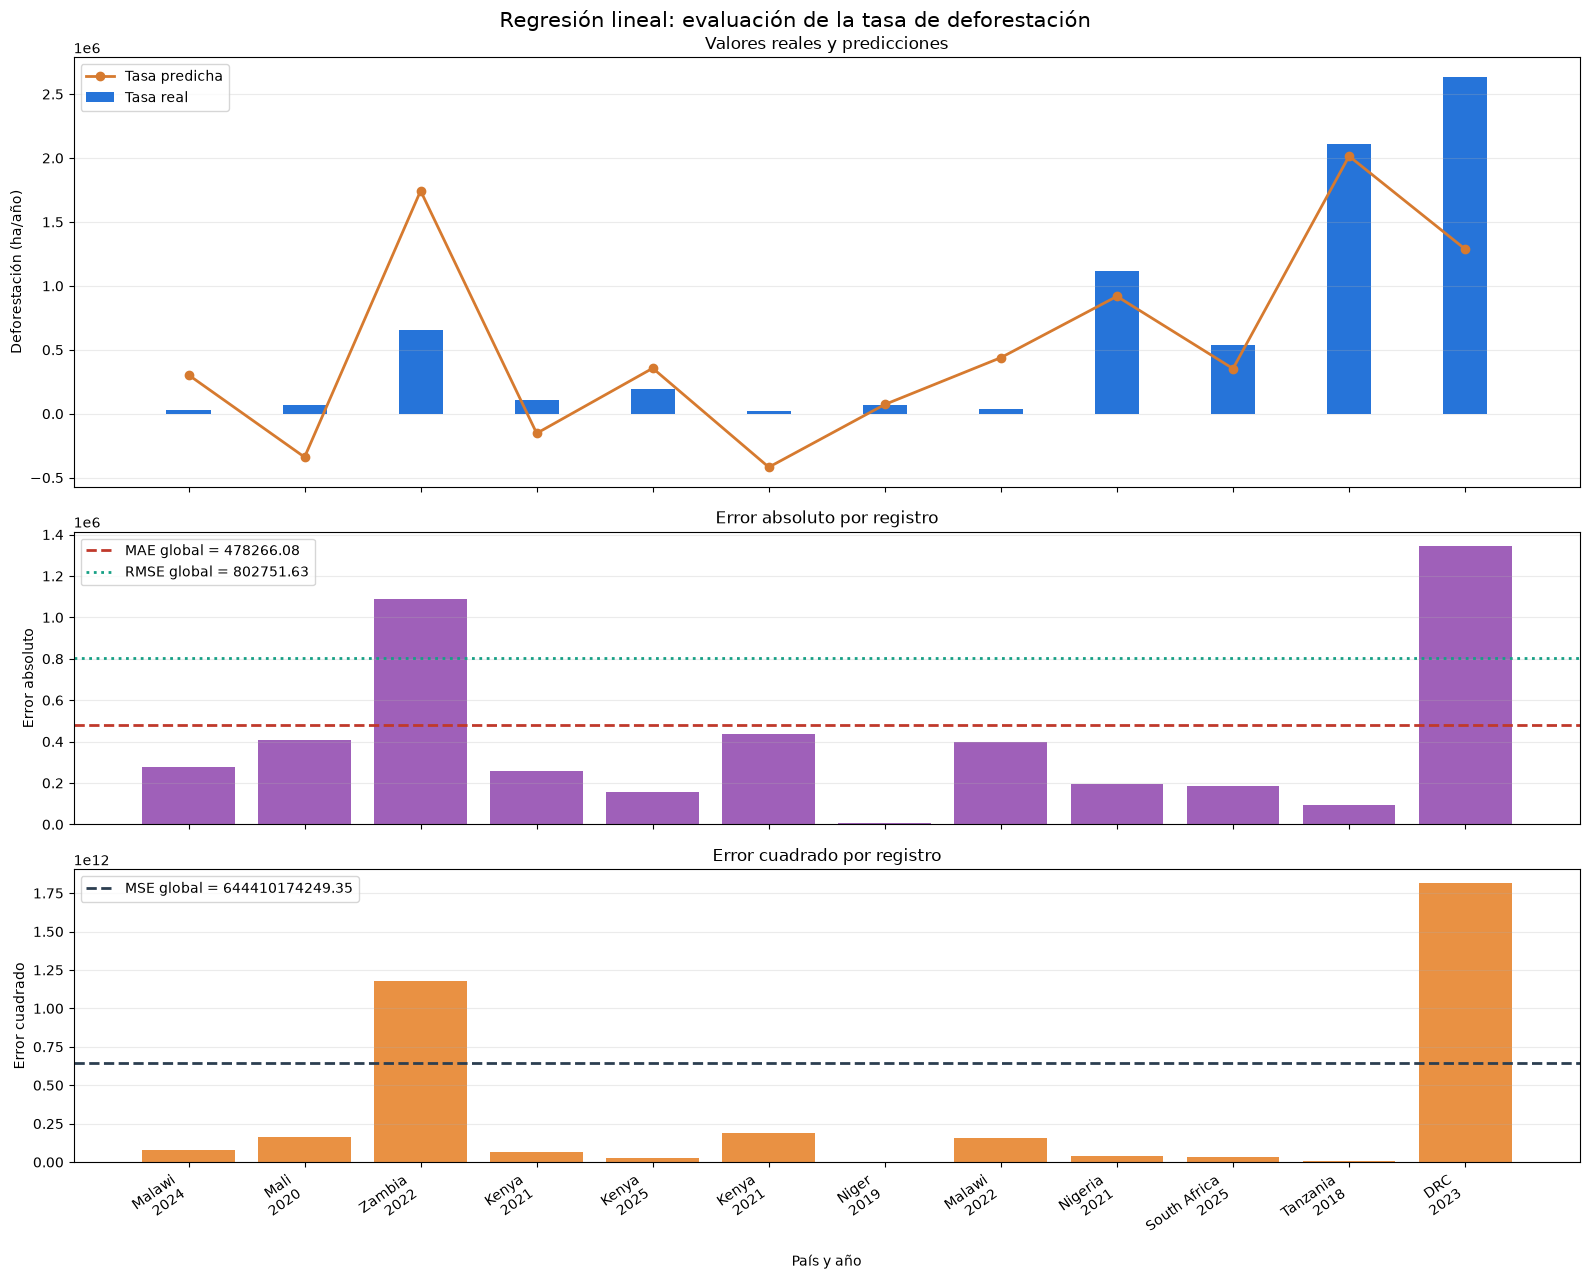

Registros mostrados: 12 de 3000
Métricas globales - MAE: 478266.08; RMSE: 802751.63; MSE: 644410174249.35
Métricas de la selección - MAE: 404238.36; RMSE: 559789.88; MSE: 313364713986.64


In [68]:

# ============================================================
# PASO 8: COMPARACIÓN DE PREDICCIONES Y ERRORES
# Adaptación del bloque de comparación del profesor
# ============================================================

indices_test = y_test.index.to_numpy()

# Valores reales y predicciones
y_test_array = y_test.to_numpy()
predicciones_array = np.asarray(predicciones)

# Seleccionar hasta 12 registros del conjunto de prueba
seleccion = np.arange(min(12, len(y_test_array)))

y_real = y_test_array[seleccion]
y_predicha = predicciones_array[seleccion]

# Calcular errores
errores = y_real - y_predicha
error_absoluto = np.abs(errores)
error_cuadrado = errores ** 2

# Etiquetas adaptadas al dataset
etiquetas = [
    f"{df.loc[indices_test[i], 'country']}\n"
    f"{df.loc[indices_test[i], 'year']}"
    for i in seleccion
]

# Métricas globales
mae_global = mean_absolute_error(y_test_array, predicciones_array)
rmse_global = np.sqrt(mean_squared_error(y_test_array, predicciones_array))
mse_global = mean_squared_error(y_test_array, predicciones_array)

posiciones = np.arange(len(seleccion))
ancho = 0.38

fig, (ax_valores, ax_absoluto, ax_cuadrado) = plt.subplots(
    3, 1,
    figsize=(16, 13),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.5, 1.5]}
)

# 1. Valores reales y predicciones
ax_valores.bar(
    posiciones, y_real, ancho,
    label="Tasa real",
    color="#2674d9"
)
ax_valores.plot(
    posiciones, y_predicha,
    color="#d67a2f",
    marker="o",
    linewidth=2,
    label="Tasa predicha"
)
ax_valores.set_ylabel("Deforestación (ha/año)")
ax_valores.set_title("Valores reales y predicciones")
ax_valores.legend()
ax_valores.grid(axis="y", alpha=0.25)

# 2. Errores absolutos
ax_absoluto.bar(
    posiciones, error_absoluto,
    color="#8e44ad",
    alpha=0.85
)
ax_absoluto.axhline(
    mae_global,
    color="#c0392b",
    linestyle="--",
    linewidth=2,
    label=f"MAE global = {mae_global:.2f}"
)
ax_absoluto.axhline(
    rmse_global,
    color="#16a085",
    linestyle=":",
    linewidth=2,
    label=f"RMSE global = {rmse_global:.2f}"
)
ax_absoluto.set_ylabel("Error absoluto")
ax_absoluto.set_title("Error absoluto por registro")
ax_absoluto.legend()
ax_absoluto.grid(axis="y", alpha=0.25)

# 3. Errores cuadrados
ax_cuadrado.bar(
    posiciones, error_cuadrado,
    color="#e67e22",
    alpha=0.85
)
ax_cuadrado.axhline(
    mse_global,
    color="#2c3e50",
    linestyle="--",
    linewidth=2,
    label=f"MSE global = {mse_global:.2f}"
)
ax_cuadrado.set_ylabel("Error cuadrado")
ax_cuadrado.set_title("Error cuadrado por registro")
ax_cuadrado.legend()
ax_cuadrado.grid(axis="y", alpha=0.25)

ax_cuadrado.set_xticks(posiciones)
ax_cuadrado.set_xticklabels(etiquetas, rotation=35, ha="right")
ax_cuadrado.set_xlabel("País y año")

fig.suptitle(
    "Regresión lineal: evaluación de la tasa de deforestación",
    fontsize=15
)
fig.tight_layout()

display(fig)
plt.close(fig)

print(f"Registros mostrados: {len(seleccion)} de {len(y_test_array)}")
print(
    f"Métricas globales - MAE: {mae_global:.2f}; "
    f"RMSE: {rmse_global:.2f}; MSE: {mse_global:.2f}"
)
print(
    f"Métricas de la selección - MAE: {error_absoluto.mean():.2f}; "
    f"RMSE: {np.sqrt(error_cuadrado.mean()):.2f}; "
    f"MSE: {error_cuadrado.mean():.2f}"
)


In [69]:

# ============================================================
# PASO 9: DIAGNÓSTICO DE CALIDAD DE LOS DATOS
# ============================================================

import pandas as pd
import numpy as np

# Evidencia antes del preprocesamiento
print("========== ANTES DEL PREPROCESAMIENTO ==========")
print(f"Filas: {len(df)}")
print(f"Columnas: {len(df.columns)}")
print(f"Duplicados exactos: {df.duplicated().sum()}")

faltantes_antes = df.isnull().sum()
print("\nValores faltantes por columna:")
print(faltantes_antes[faltantes_antes > 0].to_string()
      if faltantes_antes.any()
      else "No hay valores faltantes.")

print("\nTipos de datos:")
print(df.dtypes.to_string())

# Crear una copia para conservar el DataFrame original
df_limpio = df.copy()

# Eliminar registros duplicados exactos
df_limpio = df_limpio.drop_duplicates().copy()

# Evidencia después del preprocesamiento
print("\n========== DESPUÉS DEL PREPROCESAMIENTO ==========")
print(f"Filas: {len(df_limpio)}")
print(f"Columnas: {len(df_limpio.columns)}")
print(f"Duplicados exactos: {df_limpio.duplicated().sum()}")

faltantes_despues = df_limpio.isnull().sum()
print("\nValores faltantes por columna:")
print(faltantes_despues[faltantes_despues > 0].to_string()
      if faltantes_despues.any()
      else "No hay valores faltantes.")

print("\nFilas eliminadas por duplicación:",
      len(df) - len(df_limpio))


========== ANTES DEL PREPROCESAMIENTO ==========
Filas: 15000
Columnas: 18
Duplicados exactos: 0

Valores faltantes por columna:
No hay valores faltantes.

Tipos de datos:
record_id                        object
country                          object
year                              int64
region_type                      object
forest_cover_pct                float64
forest_area_ha                    int64
population_density              float64
agricultural_expansion_index    float64
deforestation_rate_ha_year        int64
primary_driver                   object
land_conversion_type             object
policy_strength_index           float64
protected_area_coverage         float64
biomass_loss_tonnes               int64
carbon_emission_tonnes            int64
biodiversity_impact_score       float64
climate_regulation_loss_usd       int64
recovery_potential_index        float64

========== DESPUÉS DEL PREPROCESAMIENTO ==========
Filas: 15000
Columnas: 18
Duplicados exactos: 0

Valores

In [70]:
import pandas as pd
import numpy as np

print("========== PREPARACIÓN DE DATOS PARA CLASIFICACIÓN ==========")

variables = [
    "forest_cover_pct",
    "population_density",
    "agricultural_expansion_index",
    "deforestation_rate_ha_year",
    "policy_strength_index",
    "protected_area_coverage",
    "biodiversity_impact_score",
    "recovery_potential_index",
    "year"
]

objetivo = "primary_driver"

datos_clasificacion = df_limpio.loc[:, variables + [objetivo]].copy()

# Eliminar registros que no tengan la categoría que se desea predecir
datos_clasificacion = datos_clasificacion.dropna(subset=[objetivo]).copy()

# Convertir la variable objetivo a texto mediante una asignación explícita
datos_clasificacion.loc[:, objetivo] = (
    datos_clasificacion[objetivo].astype(str)
)

X_clasificacion = datos_clasificacion.loc[:, variables].copy()
y_clasificacion = datos_clasificacion.loc[:, objetivo].copy()

print(f"Filas disponibles: {len(datos_clasificacion)}")
print(f"Número de variables predictoras: {len(variables)}")
print(f"Variable objetivo: {objetivo}")

print("\nCantidad de registros por categoría:")
print(y_clasificacion.value_counts())


========== PREPARACIÓN DE DATOS PARA CLASIFICACIÓN ==========
Filas disponibles: 15000
Número de variables predictoras: 9
Variable objetivo: primary_driver

Cantidad de registros por categoría:
primary_driver
smallholder_agriculture    5248
commercial_agriculture     3044
charcoal_production        2305
logging                    1490
mining                     1201
urban_expansion             999
infrastructure              713
Name: count, dtype: int64


In [71]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Dividir los datos: 80 % entrenamiento y 20 % prueba
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clasificacion,
    y_clasificacion,
    test_size=0.2,
    random_state=42,
    stratify=y_clasificacion
)

# Crear el flujo de preprocesamiento y clasificación
modelo_clasificacion = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("clasificador", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Entrenar el modelo
modelo_clasificacion.fit(X_train_clf, y_train_clf)

# Generar predicciones sobre datos no usados para entrenar
predicciones_clf = modelo_clasificacion.predict(X_test_clf)

print("========== ENTRENAMIENTO COMPLETADO ==========")
print(f"Registros de entrenamiento: {len(X_train_clf)}")
print(f"Registros de prueba: {len(X_test_clf)}")
print("Algoritmo: Random Forest Classifier")
print("Número de árboles: 200")
print("Semilla aleatoria: 42")


========== ENTRENAMIENTO COMPLETADO ==========
Registros de entrenamiento: 12000
Registros de prueba: 3000
Algoritmo: Random Forest Classifier
Número de árboles: 200
Semilla aleatoria: 42


========== RESULTADOS DE CLASIFICACIÓN ==========
Exactitud (Accuracy): 0.2333

Reporte de clasificación:
                         precision    recall  f1-score   support

    charcoal_production       0.13      0.14      0.14       461
 commercial_agriculture       0.22      0.24      0.23       609
         infrastructure       0.07      0.05      0.06       142
                logging       0.10      0.10      0.10       298
                 mining       0.09      0.07      0.08       240
smallholder_agriculture       0.38      0.41      0.40      1050
        urban_expansion       0.05      0.04      0.04       200

               accuracy                           0.23      3000
              macro avg       0.15      0.15      0.15      3000
           weighted avg       0.22      0.23      0.23      3000



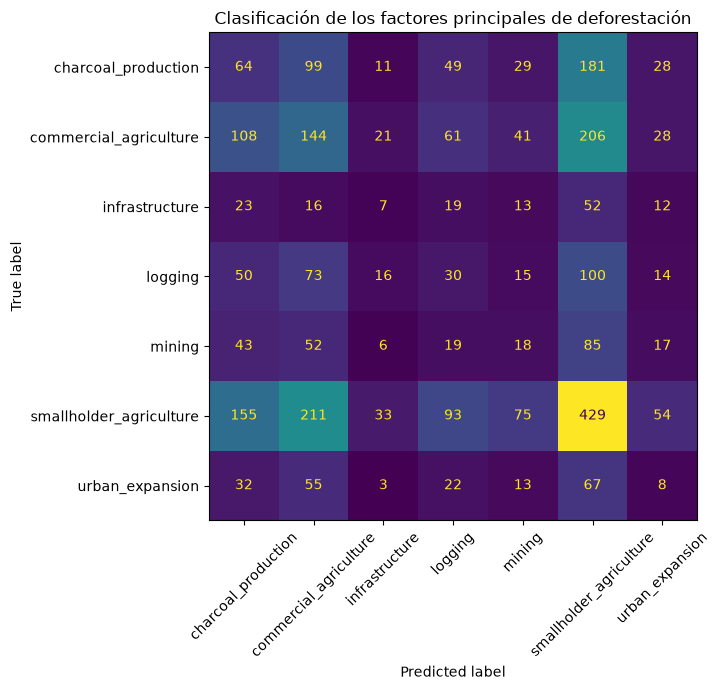

In [72]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
from IPython.display import display

# Métrica general
exactitud = accuracy_score(y_test_clf, predicciones_clf)

print("========== RESULTADOS DE CLASIFICACIÓN ==========")
print(f"Exactitud (Accuracy): {exactitud:.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test_clf,
    predicciones_clf,
    zero_division=0
))

# Matriz de confusión
matriz = confusion_matrix(
    y_test_clf,
    predicciones_clf,
    labels=modelo_clasificacion.classes_
)

fig, ax = plt.subplots(figsize=(10, 7))
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=modelo_clasificacion.classes_
)
visualizacion.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)
ax.set_title("Clasificación de los factores principales de deforestación")
plt.tight_layout()
display(fig)
plt.close(fig)


In [73]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

variables_numericas = [
    "forest_cover_pct",
    "population_density",
    "agricultural_expansion_index",
    "deforestation_rate_ha_year",
    "policy_strength_index",
    "protected_area_coverage",
    "biodiversity_impact_score",
    "recovery_potential_index",
    "year"
]

variables_categoricas = [
    "country",
    "region_type",
    "land_conversion_type"
]

variables_mejoradas = variables_numericas + variables_categoricas

datos_mejorados = df_limpio.loc[
    :, variables_mejoradas + ["primary_driver"]
].copy()

datos_mejorados = datos_mejorados.dropna(
    subset=["primary_driver"]
).copy()

X_mejorado = datos_mejorados.loc[:, variables_mejoradas]
y_mejorado = datos_mejorados.loc[:, "primary_driver"].astype(str)

X_train_mej, X_test_mej, y_train_mej, y_test_mej = train_test_split(
    X_mejorado,
    y_mejorado,
    test_size=0.2,
    random_state=42,
    stratify=y_mejorado
)

preprocesador = ColumnTransformer(transformers=[
    ("numericas", SimpleImputer(strategy="median"), variables_numericas),
    ("categoricas", Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(handle_unknown="ignore"))
    ]), variables_categoricas)
])

modelo_mejorado = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("clasificador", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

modelo_mejorado.fit(X_train_mej, y_train_mej)
predicciones_mej = modelo_mejorado.predict(X_test_mej)

accuracy_mejorado = accuracy_score(y_test_mej, predicciones_mej)

print("========== COMPARACIÓN DE CLASIFICADORES ==========")
print(f"Modelo inicial - Accuracy: {accuracy_score(y_test_clf, predicciones_clf):.4f}")
print(f"Modelo mejorado - Accuracy: {accuracy_mejorado:.4f}")

print("\nReporte del modelo mejorado:")
print(classification_report(
    y_test_mej,
    predicciones_mej,
    zero_division=0
))

========== COMPARACIÓN DE CLASIFICADORES ==========
Modelo inicial - Accuracy: 0.2333
Modelo mejorado - Accuracy: 0.2347

Reporte del modelo mejorado:
                         precision    recall  f1-score   support

    charcoal_production       0.15      0.16      0.15       461
 commercial_agriculture       0.23      0.24      0.23       609
         infrastructure       0.05      0.02      0.03       142
                logging       0.09      0.08      0.08       298
                 mining       0.09      0.07      0.08       240
smallholder_agriculture       0.36      0.41      0.39      1050
        urban_expansion       0.06      0.04      0.05       200

               accuracy                           0.23      3000
              macro avg       0.15      0.15      0.15      3000
           weighted avg       0.22      0.23      0.23      3000



#### Interpretación 
- Rendimiento general: el modelo mejorado alcanzó una exactitud de 0,2347, es decir, clasificó correctamente cerca del 23,47 % de los registros de prueba.
- Categoría mejor identificada: smallholder_agriculture, con F1-score de 0,39 en el modelo mejorado.
- Categorías difíciles de identificar: infrastructure obtuvo F1-score de 0,03 y urban_expansion, de 0,05.
- Efecto de las variables categóricas: incorporar país, tipo de región y tipo de conversión del terreno apenas modificó el rendimiento. Por tanto, esa modificación no solucionó el problema de clasificación.
- Conclusión: el modelo presenta limitaciones importantes para distinguir las siete categorías.

In [74]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

# Modelo de referencia: siempre predice la categoría más frecuente
modelo_referencia = DummyClassifier(strategy="most_frequent")
modelo_referencia.fit(X_train_mej, y_train_mej)

predicciones_referencia = modelo_referencia.predict(X_test_mej)

accuracy_referencia = accuracy_score(
    y_test_mej, predicciones_referencia
)

f1_macro_referencia = f1_score(
    y_test_mej,
    predicciones_referencia,
    average="macro",
    zero_division=0
)

f1_macro_mejorado = f1_score(
    y_test_mej,
    predicciones_mej,
    average="macro",
    zero_division=0
)

print("========== COMPARACIÓN FINAL ==========")
print(f"Modelo de referencia - Accuracy: {accuracy_referencia:.4f}")
print(f"Random Forest inicial - Accuracy: {accuracy_score(y_test_clf, predicciones_clf):.4f}")
print(f"Random Forest mejorado - Accuracy: {accuracy_mejorado:.4f}")

print(f"\nModelo de referencia - F1 macro: {f1_macro_referencia:.4f}")
print(f"Random Forest mejorado - F1 macro: {f1_macro_mejorado:.4f}")


========== COMPARACIÓN FINAL ==========
Modelo de referencia - Accuracy: 0.3500
Random Forest inicial - Accuracy: 0.2333
Random Forest mejorado - Accuracy: 0.2347

Modelo de referencia - F1 macro: 0.0741
Random Forest mejorado - F1 macro: 0.1451


In [75]:
# ============================================================
# GENERACIÓN DEL REPORTE DE RESULTADOS
# ============================================================

# Importamos las herramientas necesarias.
from pathlib import Path
from datetime import datetime
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np


# ------------------------------------------------------------
# 1. DEFINIR LA CARPETA Y EL NOMBRE DEL ARCHIVO
# ------------------------------------------------------------

# Establecemos la ruta donde se guardarán los reportes.
ruta_reportes = Path(
    "/workspaces/MachineLearning/src/sincronicas/reportes"
)

# Creamos la carpeta si todavía no existe.
# parents=True permite crear las carpetas intermedias necesarias.
# exist_ok=True evita un error si la carpeta ya existe.
ruta_reportes.mkdir(parents=True, exist_ok=True)

# Definimos la ruta completa y el nombre del archivo de salida.
ruta_resumen = ruta_reportes / "africa-synth-climate-deforestation-land-use-change-all.txt"


# ------------------------------------------------------------
# 2. CALCULAR LAS MÉTRICAS DE REGRESIÓN
# ------------------------------------------------------------

# MAE: calcula el error absoluto medio entre valores reales
# y valores predichos. Cuanto menor sea, mejor.
mae = mean_absolute_error(y_test, predicciones)

# RMSE: calcula la raíz del error cuadrático medio.
# Penaliza más los errores grandes. Cuanto menor sea, mejor.
rmse = np.sqrt(mean_squared_error(y_test, predicciones))

# R²: mide qué tan bien se ajustan las predicciones a los datos.
# Un valor cercano a 1 indica mejor ajuste; puede ser negativo.
r2 = r2_score(y_test, predicciones)


# ------------------------------------------------------------
# 3. CALCULAR LAS MÉTRICAS DE CLASIFICACIÓN
# ------------------------------------------------------------

# Calculamos la exactitud del modelo de referencia.
# Este modelo predice siempre la clase más frecuente.
accuracy_referencia = accuracy_score(
    y_test_mej, predicciones_referencia
)

# Calculamos la exactitud del modelo Random Forest mejorado.
accuracy_mejorado = accuracy_score(
    y_test_mej, predicciones_mej
)

# El F1 macro calcula el F1 de cada clase y luego promedia
# todas las clases por igual, sin favorecer a la mayoritaria.
f1_macro_referencia = f1_score(
    y_test_mej,
    predicciones_referencia,
    average="macro",
    zero_division=0
)

f1_macro_mejorado = f1_score(
    y_test_mej,
    predicciones_mej,
    average="macro",
    zero_division=0
)

# Generamos el reporte detallado por clase del modelo mejorado.
reporte_clasificacion = classification_report(
    y_test_mej,
    predicciones_mej,
    zero_division=0
)


# ------------------------------------------------------------
# 4. ORGANIZAR EL CONTENIDO DEL REPORTE
# ------------------------------------------------------------

# Creamos una lista de líneas que contendrá todo el texto.
# datetime.now() registra la fecha y hora de generación.
lineas = [
    "REPORTE DE RESULTADOS ",
    "=" * 55,
    f"Fecha de generación: {datetime.now():%Y-%m-%d %H:%M:%S}",
    "",
    "DATASET UTILIZADO",
    "-" * 55,
    "Nombre: electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all",
    "Fuente: https://huggingface.co/datasets/electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all",
    "Nota: los datos son sintéticos; los resultados no demuestran causalidad ni representan necesariamente condiciones reales.",
    "",
    "1. RESULTADOS DEL MODELO DE REGRESIÓN LINEAL",
    "-" * 55,
    "Variable objetivo: deforestation_rate_ha_year",
    f"MAE: {mae:.4f}",
    f"RMSE: {rmse:.4f}",
    f"R²: {r2:.4f}",
    "",
    "Interpretación de las métricas:",
    "- MAE y RMSE miden el error de las predicciones; valores menores son preferibles.",
    "- R² mide el ajuste del modelo; debe interpretarse junto con los errores.",
    "",
    "2. RESULTADOS DEL MODELO DE CLASIFICACIÓN",
    "-" * 55,
    "Modelo: Random Forest mejorado",
    "Variable objetivo: primary_driver",
    f"Accuracy del modelo de referencia: {accuracy_referencia:.4f}",
    f"Accuracy del Random Forest mejorado: {accuracy_mejorado:.4f}",
    f"F1 macro del modelo de referencia: {f1_macro_referencia:.4f}",
    f"F1 macro del Random Forest mejorado: {f1_macro_mejorado:.4f}",
    "",
    "Reporte detallado por clase:",
    reporte_clasificacion,
    "",
    "3. COMPARACIÓN E INTERPRETACIÓN",
    "-" * 55,
    (
        "El modelo de referencia obtiene mayor accuracy."
        if accuracy_referencia > accuracy_mejorado
        else "El Random Forest mejorado obtiene mayor accuracy."
        if accuracy_mejorado > accuracy_referencia
        else "Ambos modelos obtienen la misma accuracy."
    ),
    (
        "El Random Forest mejorado obtiene mayor F1 macro."
        if f1_macro_mejorado > f1_macro_referencia
        else "El modelo de referencia obtiene mayor F1 macro."
        if f1_macro_referencia > f1_macro_mejorado
        else "Ambos modelos obtienen el mismo F1 macro."
    ),
    "",
    "Los resultados deben interpretarse considerando el carácter sintético",
    "del dataset y el rendimiento observado en los datos de prueba.",
    "",
    "FIN DEL REPORTE"
]


# ------------------------------------------------------------
# 5. GUARDAR EL REPORTE COMO ARCHIVO TXT
# ------------------------------------------------------------

# Unimos las líneas con saltos de línea para formar el texto.
contenido = "\n".join(lineas) + "\n"

# Guardamos el texto en el archivo usando codificación UTF-8,
# compatible con tildes y otros caracteres especiales.
ruta_resumen.write_text(contenido, encoding="utf-8")


# ------------------------------------------------------------
# 6. MOSTRAR EL RESULTADO Y CONFIRMAR LA UBICACIÓN
# ------------------------------------------------------------

# Imprimimos el contenido para revisarlo directamente
# en la salida de la celda de Jupyter Notebook.
print(contenido)

# Mostramos la ubicación completa del archivo generado.
print("Reporte guardado correctamente en:")
print(ruta_resumen.resolve())


REPORTE DE RESULTADOS 
Fecha de generación: 2026-10-26 03:42:53

DATASET UTILIZADO
-------------------------------------------------------
Nombre: electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all
Fuente: https://huggingface.co/datasets/electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all
Nota: los datos son sintéticos; los resultados no demuestran causalidad ni representan necesariamente condiciones reales.

1. RESULTADOS DEL MODELO DE REGRESIÓN LINEAL
-------------------------------------------------------
Variable objetivo: deforestation_rate_ha_year
MAE: 478266.0801
RMSE: 802751.6267
R²: 0.4084

Interpretación de las métricas:
- MAE y RMSE miden el error de las predicciones; valores menores son preferibles.
- R² mide el ajuste del modelo; debe interpretarse junto con los errores.

2. RESULTADOS DEL MODELO DE CLASIFICACIÓN
-------------------------------------------------------
Modelo: Random Forest mejorado
Variable objetivo: primary_d